In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install segmentation_models_pytorch h5py ultralytics

Mounted at /content/drive


In [ ]:
import os, glob, re, json, random, time, shutil
import numpy as np, pandas as pd, h5py, torch
import torch.nn as nn, torch.nn.functional as F, torch.optim as optim
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

PH3 = '/content/drive/MyDrive/TerraSeg/phase3'
OUT = '/content/drive/MyDrive/TerraSeg/phase7'
os.makedirs(f'{OUT}/runs', exist_ok=True)

SEEDS = [42,123,777]            # FIRST pass: one seed. Then change to [42, 123, 777] and re-run Part C (finished runs are skipped)
EPOCHS, PATIENCE, LR, BATCH = 40, 10, 5e-4, 16
FORCE = False

# channels 0-11 = Sentinel-2 bands B1..B12, 12 = slope, 13 = DEM. RGB = B4,B3,B2 = channels 3,2,1
VARIANTS = {
    'RGB':           [3, 2, 1],
    'RGB+slope':     [3, 2, 1, 12],
    'RGB+slope+DEM': [3, 2, 1, 12, 13],
    'Optical12':     list(range(12)),
    'Optical12+slope': list(range(13)),
    'All14':         list(range(14)),
}

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device, "| variants:", {k: len(v) for k, v in VARIANTS.items()})

Device: cuda | variants: {'RGB': 3, 'RGB+slope': 4, 'RGB+slope+DEM': 5, 'Optical12': 12, 'Optical12+slope': 13, 'All14': 14}


In [ ]:
from huggingface_hub import snapshot_download
snapshot_download(repo_id="ibm-nasa-geospatial/Landslide4sense", repo_type="dataset",
                  allow_patterns=["*train*"], local_dir="/content/l4s", max_workers=8)

def num(p): return int(re.findall(r'(\d+)\.h5$', p)[0])
img_files  = sorted(glob.glob('/content/l4s/images/train/image_*.h5'), key=num)
mask_files = sorted(glob.glob('/content/l4s/annotations/train/mask_*.h5'), key=num)
assert len(img_files) == len(mask_files) > 0
assert all(num(a) == num(b) for a, b in zip(img_files, mask_files)), "image/mask mismatch"
def first(h): return h[list(h.keys())[0]][:]

N = len(img_files)
X = np.zeros((N, 14, 128, 128), np.float32)
Y = np.zeros((N, 1, 128, 128), np.float32)
for i, (a, b) in enumerate(tqdm(list(zip(img_files, mask_files)))):
    with h5py.File(a) as h: X[i] = np.nan_to_num(first(h)).transpose(2, 0, 1)
    with h5py.File(b) as h: Y[i, 0] = first(h)

sp = np.load(f'{PH3}/split.npz')
train_idx, val_idx, test_idx = sp['train'], sp['val'], sp['test']
print(f"patches {N} | train {len(train_idx)} | val {len(val_idx)} | test {len(test_idx)}")
print(f"landslide share  train {Y[train_idx].mean()*100:.2f}% | val {Y[val_idx].mean()*100:.2f}% | test {Y[test_idx].mean()*100:.2f}%")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7603 files:   0%|          | 0/7603 [00:00<?, ?it/s]

  0%|          | 0/3799 [00:00<?, ?it/s]

patches 3799 | train 2659 | val 569 | test 571
landslide share  train 2.31% | val 2.45% | test 2.21%


In [ ]:
if globals().get('NORMALISED', False):
    raise RuntimeError("X is already normalised. Restart the session (Runtime -> Restart session) and run from the top.")

s1 = np.zeros(14, np.float64); s2 = np.zeros(14, np.float64); cnt = 0
for s in range(0, len(train_idx), 256):
    b = X[np.sort(train_idx[s:s + 256])].astype(np.float64)
    s1 += b.sum(axis=(0, 2, 3)); s2 += (b ** 2).sum(axis=(0, 2, 3)); cnt += b.shape[0] * 128 * 128
MEAN = (s1 / cnt).astype(np.float32)
STD = (np.sqrt(np.maximum(s2 / cnt - (s1 / cnt) ** 2, 1e-12)) + 1e-6).astype(np.float32)
json.dump({'mean': MEAN.tolist(), 'std': STD.tolist()}, open(f'{OUT}/norm_stats.json', 'w'))

for s in range(0, N, 256):
    X[s:s + 256] = (X[s:s + 256] - MEAN.reshape(1, 14, 1, 1)) / STD.reshape(1, 14, 1, 1)
NORMALISED = True

chk = X[train_idx[:200]]
print("after normalising (train sample): channel means within", float(np.abs(chk.mean(axis=(0, 2, 3))).max()), "of 0;",
      "stds between", float(chk.std(axis=(0, 2, 3)).min()), "and", float(chk.std(axis=(0, 2, 3)).max()))

after normalising (train sample): channel means within 0.14134201407432556 of 0; stds between 0.9769036173820496 and 1.2108635902404785


In [ ]:
class PatchDS(Dataset):
    def __init__(self, idx, chans, aug=False):
        self.idx, self.chans, self.aug = np.asarray(idx), list(chans), aug
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        x = torch.from_numpy(X[j][self.chans])           # (C,128,128), a copy
        y = torch.from_numpy(Y[j].copy())
        if self.aug:
            if random.random() > 0.5: x, y = x.flip(-1), y.flip(-1)
            if random.random() > 0.5: x, y = x.flip(-2), y.flip(-2)
        return x, y

def loader(idx, chans, aug=False, shuffle=False, bs=BATCH, seed=0):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(PatchDS(idx, chans, aug), batch_size=bs, shuffle=shuffle,
                      generator=g if shuffle else None, num_workers=2, pin_memory=True)
print("dataset ready")

dataset ready


In [ ]:
class EncoderWithC2PSA(nn.Module):
    # wraps a segmentation_models_pytorch encoder and applies C2PSA to its deepest feature map
    def __init__(self, encoder, c2psa_cls):
        super().__init__()
        self.encoder = encoder
        c = encoder.out_channels[-1]                         # 512 for ResNet34
        self.c2psa = c2psa_cls(c, c, n=1, e=0.5)
        self.out_channels = encoder.out_channels
        self.output_stride = getattr(encoder, 'output_stride', 32)   # needed by newer smp versions
    def forward(self, x):
        feats = list(self.encoder(x))
        feats[-1] = self.c2psa(feats[-1])
        return feats

def build_model(n_ch, c2psa=False, pretrained=True):
    m = smp.Unet('resnet34', encoder_weights='imagenet' if pretrained else None, in_channels=n_ch, classes=1)
    if c2psa:
        from ultralytics.nn.modules import C2PSA
        m.encoder = EncoderWithC2PSA(m.encoder, C2PSA)
    return m.to(device)

for flag in (False, True):
    m = build_model(4, c2psa=flag, pretrained=False)
    out = m(torch.randn(2, 4, 128, 128, device=device))
    print(f"C2PSA={flag}: output {tuple(out.shape)} | parameters {sum(p.numel() for p in m.parameters())/1e6:.2f} M")
    del m

C2PSA=False: output (2, 1, 128, 128) | parameters 24.44 M
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
C2PSA=True: output (2, 1, 128, 128) | parameters 25.43 M


In [ ]:
def dice_term(logits, t):
    p, tf = torch.sigmoid(logits).view(-1), t.view(-1)
    return 1 - (2 * (p * tf).sum() + 1e-6) / (p.sum() + tf.sum() + 1e-6)

class BCEDiceLoss(nn.Module):
    def forward(self, logits, t):
        return F.binary_cross_entropy_with_logits(logits, t) + dice_term(logits, t)

@torch.no_grad()
def collect_probs(model, ldr):
    model.eval()
    P, T = [], []
    for x, y in ldr:
        P.append(torch.sigmoid(model(x.to(device)))[:, 0].cpu().numpy().astype(np.float16))
        T.append(y[:, 0].numpy().astype(np.uint8))
    return np.concatenate(P), np.concatenate(T)

def metrics_from_probs(P, T, thr=0.5):
    p, t = P.astype(np.float32) > thr, T == 1
    tp, fp = float((p & t).sum()), float((p & ~t).sum())
    fn, tn = float((~p & t).sum()), float((~p & ~t).sum())
    e = 1e-9
    prec, rec = tp / (tp + fp + e), tp / (tp + fn + e)
    return {'IoU': tp / (tp + fp + fn + e), 'F1': 2 * prec * rec / (prec + rec + e), 'Precision': prec, 'Recall': rec,
            'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn}

def rpath(name, seed): return f"{OUT}/runs/{name.replace('+', '_')}_s{seed}.json"
def cpath(name, seed): return f"{OUT}/runs/{name.replace('+', '_')}_s{seed}.pth"

def run_experiment(name, chans, seed, c2psa=False):
    if os.path.exists(rpath(name, seed)) and not FORCE:
        print(f"skip {name} seed {seed} (done)")
        return json.load(open(rpath(name, seed)))
    print("\n" + "=" * 70 + f"\n{name} | seed {seed} | {len(chans)} channels | C2PSA={c2psa}\n" + "=" * 70)
    set_seed(seed)
    tr = loader(train_idx, chans, True, True, BATCH, seed)
    va, te = loader(val_idx, chans, False, False, 32), loader(test_idx, chans, False, False, 32)
    model = build_model(len(chans), c2psa); crit = BCEDiceLoss()
    opt = optim.Adam(model.parameters(), lr=LR)
    best, bad, ran, t0 = -1.0, 0, 0, time.time()
    for ep in range(EPOCHS):
        model.train(); run = 0.0
        for x, y in tr:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = crit(model(x), y); loss.backward(); opt.step(); run += loss.item()
        Pv, Tv = collect_probs(model, va); v = metrics_from_probs(Pv, Tv); ran = ep + 1
        print(f"[{name}/{seed}] ep {ran:02d} train {run/len(tr):.4f} | val IoU {v['IoU']:.4f}  ({time.time()-t0:.0f}s)")
        if v['IoU'] > best:
            best, bad = v['IoU'], 0; torch.save(model.state_dict(), cpath(name, seed))
        else:
            bad += 1
            if bad >= PATIENCE:
                print("early stopping"); break
    model.load_state_dict(torch.load(cpath(name, seed), map_location=device))
    Pv, Tv = collect_probs(model, va); Pt, Tt = collect_probs(model, te)
    res = {'name': name, 'seed': seed, 'channels': list(chans), 'c2psa': c2psa, 'epochs_run': ran,
           'val': metrics_from_probs(Pv, Tv), 'test': metrics_from_probs(Pt, Tt)}
    json.dump(res, open(rpath(name, seed), 'w'))
    t = res['test']
    print(f"TEST -> IoU {t['IoU']:.4f} | F1 {t['F1']:.4f} | P {t['Precision']:.4f} | R {t['Recall']:.4f} | FP pixels {t['fp']:.0f}")
    del model, opt; torch.cuda.empty_cache()
    return res

print("training code ready")

training code ready


In [ ]:
RUN_VARIANTS = ['RGB', 'RGB+slope', 'All14']
for seed in SEEDS:
    for name in RUN_VARIANTS:
        run_experiment(name, VARIANTS[name], seed)

skip RGB seed 42 (done)
skip RGB+slope seed 42 (done)
skip All14 seed 42 (done)
skip RGB seed 123 (done)
skip RGB+slope seed 123 (done)
skip All14 seed 123 (done)
skip RGB seed 777 (done)
skip RGB+slope seed 777 (done)
skip All14 seed 777 (done)


In [ ]:
def load_runs(include_c2psa=False):
    rows = []
    for f in sorted(glob.glob(f'{OUT}/runs/*.json')):
        r = json.load(open(f))
        if r['c2psa'] and not include_c2psa: continue
        row = {'variant': r['name'], 'seed': r['seed'], 'epochs': r['epochs_run']}
        row.update({f'test_{k}': v for k, v in r['test'].items()})
        row.update({f'val_{k}': v for k, v in r['val'].items()})
        rows.append(row)
    return pd.DataFrame(rows)

def summarise(df, order, ref='RGB'):
    g = df.groupby('variant')
    tab = pd.DataFrame({
        'runs': g.size(), 'IoU': g['test_IoU'].mean(), 'IoU std': g['test_IoU'].std(),
        'F1': g['test_F1'].mean(), 'Precision': g['test_Precision'].mean(), 'Recall': g['test_Recall'].mean(),
        'FP pixels': g['test_fp'].mean(), 'val_IoU': g['val_IoU'].mean()}).reindex([o for o in order if o in g.groups])
    tab['IoU gain vs RGB'] = tab['IoU'] - tab.loc[ref, 'IoU']
    pooled = np.sqrt((tab['IoU std'] ** 2 + tab.loc[ref, 'IoU std'] ** 2) / 2)
    tab['gain / std'] = tab['IoU gain vs RGB'] / pooled
    tab['FP reduction vs RGB %'] = (tab.loc[ref, 'FP pixels'] - tab['FP pixels']) / tab.loc[ref, 'FP pixels'] * 100
    return tab

df_runs = load_runs()
tab = summarise(df_runs, list(VARIANTS))
display(tab.round(4))
tab.round(4).to_csv(f'{OUT}/phase7_channel_study.csv')
best_variant = tab['val_IoU'].idxmax()
print("Best variant by VALIDATION IoU:", best_variant)

,runs,IoU,IoU std,F1,Precision,Recall,FP pixels,val_IoU,IoU gain vs RGB,gain / std,FP reduction vs RGB %
variant,,,,,,,,,,,
RGB,3,0.5716,0.0024,0.7274,0.7070,0.7492,64304.3333,0.5641,0.0000,0.0000,0.0000
RGB+slope,3,0.5882,0.0122,0.7406,0.7093,0.7753,65827.6667,0.5867,0.0166,1.8933,-2.3689
RGB+slope+DEM,1,0.5822,NaN,0.7359,0.7360,0.7359,54627.0000,0.5913,0.0106,NaN,15.0493
Optical12,1,0.5471,NaN,0.7073,0.7273,0.6883,53409.0000,0.5619,-0.0245,NaN,16.9434
Optical12+slope,1,0.5965,NaN,0.7473,0.7342,0.7607,56988.0000,0.6030,0.0249,NaN,11.3777
All14,3,0.6079,0.0069,0.7562,0.7500,0.7627,52714.0000,0.6087,0.0363,7.0337,18.0242


Best variant by VALIDATION IoU: All14


In [ ]:
TARGET_RECALL = 0.70

def fp_at_recall(name, chans, c2psa=False, seed=42, target=TARGET_RECALL):
    model = build_model(len(chans), c2psa, pretrained=False)
    model.load_state_dict(torch.load(cpath(name, seed), map_location=device)); model.eval()
    Pv, Tv = collect_probs(model, loader(val_idx, chans, False, False, 32))
    Pt, Tt = collect_probs(model, loader(test_idx, chans, False, False, 32))
    chosen = 0.05
    for thr in np.arange(0.95, 0.049, -0.05):                    # highest threshold that still reaches the target recall on VAL
        if metrics_from_probs(Pv, Tv, thr)['Recall'] >= target:
            chosen = float(thr); break
    m = metrics_from_probs(Pt, Tt, chosen)
    del model; torch.cuda.empty_cache()
    return {'variant': name, 'threshold': round(chosen, 2), 'test recall': round(m['Recall'], 3),
            'test precision': round(m['Precision'], 3), 'FP pixels': int(m['fp'])}

rows = [fp_at_recall(n, c) for n, c in VARIANTS.items() if os.path.exists(cpath(n, 42))]
fp_tab = pd.DataFrame(rows).set_index('variant')
fp_tab['FP reduction vs RGB %'] = (fp_tab.loc['RGB', 'FP pixels'] - fp_tab['FP pixels']) / fp_tab.loc['RGB', 'FP pixels'] * 100
display(fp_tab.round(2))
fp_tab.round(2).to_csv(f'{OUT}/phase7_false_alarms_at_recall.csv')
target_met = fp_tab['FP reduction vs RGB %'].max()
print(f"Largest false-alarm reduction vs RGB at ~{int(TARGET_RECALL*100)}% recall: {target_met:.1f}% (proposal target: 15%)")

,threshold,test recall,test precision,FP pixels,FP reduction vs RGB %
variant,,,,,
RGB,0.60,0.72,0.73,56708,0.00
RGB+slope,0.85,0.75,0.76,48730,14.07
RGB+slope+DEM,0.70,0.70,0.76,45104,20.46
Optical12,0.50,0.69,0.73,53409,5.82
Optical12+slope,0.80,0.71,0.78,42710,24.68
All14,0.85,0.71,0.79,40065,29.35


Largest false-alarm reduction vs RGB at ~70% recall: 29.3% (proposal target: 15%)


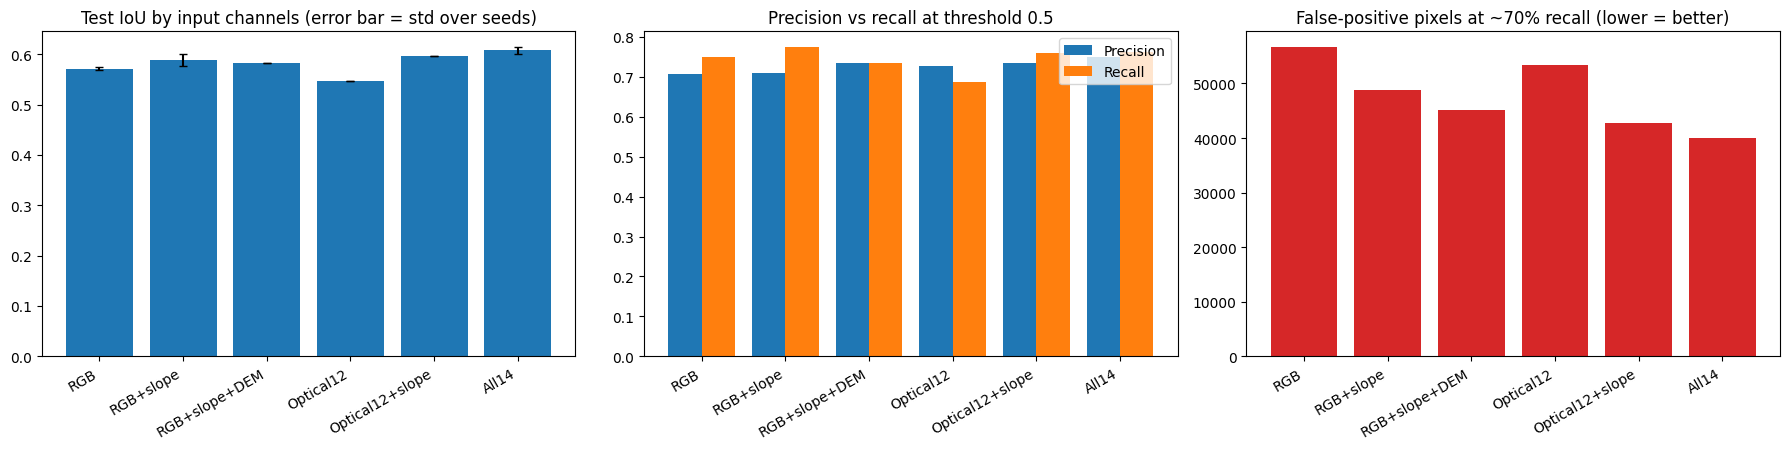

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
names = list(tab.index); xs = np.arange(len(names))
err = tab['IoU std'].fillna(0).values if tab['runs'].max() > 1 else None
ax[0].bar(xs, tab['IoU'].values, yerr=err, capsize=3, color='tab:blue'); ax[0].set_xticks(xs); ax[0].set_xticklabels(names, rotation=30, ha='right')
ax[0].set_title("Test IoU by input channels (error bar = std over seeds)")
ax[1].bar(xs - 0.2, tab['Precision'].values, 0.4, label='Precision'); ax[1].bar(xs + 0.2, tab['Recall'].values, 0.4, label='Recall')
ax[1].set_xticks(xs); ax[1].set_xticklabels(names, rotation=30, ha='right'); ax[1].legend(); ax[1].set_title("Precision vs recall at threshold 0.5")
ax[2].bar(range(len(fp_tab)), fp_tab['FP pixels'].values, color='tab:red')
ax[2].set_xticks(range(len(fp_tab))); ax[2].set_xticklabels(fp_tab.index, rotation=30, ha='right'); ax[2].set_title(f"False-positive pixels at ~{int(TARGET_RECALL*100)}% recall (lower = better)")
plt.tight_layout(); plt.savefig(f'{OUT}/phase7_channel_study.png', dpi=150); plt.show()

In [ ]:
best_chans = VARIANTS[best_variant]
c2_name = f"{best_variant}+C2PSA"
print("Applying C2PSA to:", best_variant)
for seed in SEEDS:
    run_experiment(c2_name, best_chans, seed, c2psa=True)

df_all = load_runs(include_c2psa=True)
sub = df_all[df_all['variant'].isin([best_variant, c2_name])]
g = sub.groupby('variant')
cmp = pd.DataFrame({'runs': g.size(), 'IoU': g['test_IoU'].mean(), 'IoU std': g['test_IoU'].std(),
                    'F1': g['test_F1'].mean(), 'Precision': g['test_Precision'].mean(), 'Recall': g['test_Recall'].mean()})
display(cmp.round(4))
gain = cmp.loc[c2_name, 'IoU'] - cmp.loc[best_variant, 'IoU']
pooled = np.sqrt((cmp['IoU std'] ** 2).mean()) if cmp['runs'].min() > 1 else float('nan')
print(f"C2PSA IoU gain: {gain:+.4f}" + (f"  | gain / std = {gain / pooled:.1f}" if pooled == pooled else "  | (need 3 seeds for gain / std)"))
cmp.round(4).to_csv(f'{OUT}/phase7_c2psa.csv')

Applying C2PSA to: All14
skip All14+C2PSA seed 42 (done)
skip All14+C2PSA seed 123 (done)
skip All14+C2PSA seed 777 (done)


,runs,IoU,IoU std,F1,Precision,Recall
variant,,,,,,
All14,3,0.6079,0.0069,0.7562,0.750,0.7627
All14+C2PSA,3,0.6078,0.0046,0.7561,0.752,0.7602


C2PSA IoU gain: -0.0001  | gain / std = -0.0


In [ ]:
summary = {'channel_study': tab.round(4).reset_index().to_dict('records'),
           'false_alarms_at_recall': fp_tab.round(2).reset_index().to_dict('records'),
           'c2psa': cmp.round(4).reset_index().to_dict('records'), 'seeds_used': sorted(df_runs['seed'].unique().tolist())}
json.dump(summary, open(f'{OUT}/phase7_summary.json', 'w'), indent=1)
print("saved", f'{OUT}/phase7_summary.json')
print("Seeds used:", summary['seeds_used'])

saved /content/drive/MyDrive/TerraSeg/phase7/phase7_summary.json
Seeds used: [42, 123, 777]
